# AMR Resistance Prediction — 8 Antibiotics × 5 Feature Combinations
**Antibiotics:** Amoxicillin/Clavulanic Acid, Cefuroxime, Doxycycline, Levofloxacin, Nalidixic Acid, Norfloxacin, Streptomycin, Tetracycline  
**Models:** XGBoost, RandomForest, ExtraTrees, GradientBoosting  
**Validation:** 6-fold Stratified Cross-Validation  
**Phase 1:** Train & compare all combinations  
**Phase 2:** SNP feature selection on best performers

In [1]:
# ── CELL 1: Install & Imports ──────────────────────────────────────────────
!pip install xgboost imbalanced-learn -q

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('✓ Setup complete!')
print(f'Pandas: {pd.__version__}  |  NumPy: {np.__version__}' )

✓ Setup complete!
Pandas: 2.2.2  |  NumPy: 1.26.4


In [2]:
# ── CELL 2: Configuration ─────────────────────────────────────────────────

# ⚠ Update this path to your folder containing all 40 CSV files
DATA_DIR = 'C:/Users/USER/Downloads/E_coli/datasets/final_merged_outputs'

# Antibiotic short-names must match your filename prefixes exactly
ANTIBIOTICS = {
    'amoxicillin': 'Phenotype_Label',
    'coxime'     : 'Phenotype_Label',
    'doxy'       : 'Phenotype_Label',
    'levo'       : 'Phenotype_Label',
    'nali'       : 'Phenotype_Label',
    'norflo'     : 'Phenotype_Label',
    'strep'      : 'Phenotype_Label',
    'tetra'      : 'Phenotype_Label',
}

# Dataset suffixes — must match your file naming exactly
DATASET_TYPES = [
    'ALL_FEATURES',
    'SNPS_GENES',
    'SNPS_KMERS',
    'GENES_KMERS',
    'SNPS_ONLY',
]

CONFIG = {
    'n_folds'       : 6,
    'random_state'  : RANDOM_STATE,
    'smote_strategy': 0.5,   # oversample resistant to 50% of majority class
    'top_n_features': 30,
}

print('Configuration:')
for k, v in CONFIG.items():
    print(f'  {k}: {v}')
print(f'\nAntibiotics : {len(ANTIBIOTICS)}')
print(f'Dataset types: {len(DATASET_TYPES)}')
print(f'Total files  : {len(ANTIBIOTICS) * len(DATASET_TYPES)}')

Configuration:
  n_folds: 6
  random_state: 42
  smote_strategy: 0.5
  top_n_features: 30

Antibiotics : 8
Dataset types: 5
Total files  : 40


In [3]:
# ── CELL 3: Helper Functions ──────────────────────────────────────────────

def build_filepath(antibiotic_prefix, dataset_type):
    """Build full file path from prefix and dataset type."""
    filename = f'{antibiotic_prefix}_{dataset_type}.csv'
    return os.path.join(DATA_DIR, filename)


def load_data(filepath, label_col):
    """Load CSV, separate features and label."""
    df = pd.read_csv(filepath)

    # Drop Genome_ID and the label column to get features
    drop_cols = ['Genome_ID', label_col]
    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    y = df[label_col]

    assert y.isin([0, 1]).all(), f'Labels must be 0/1 — found: {y.unique()}'

    print(f'  ✓ {len(X)} samples × {X.shape[1]} features')
    print(f'    Susceptible (0): {(y==0).sum()}  |  Resistant (1): {(y==1).sum()}')
    return X, y


def get_models(scale_pos_weight):
    """Return dict of models."""
    return {
        'XGBoost': XGBClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            subsample=0.8, colsample_bytree=0.5,
            reg_alpha=1, reg_lambda=1,
            random_state=CONFIG['random_state'],
            eval_metric='logloss', verbosity=0
        ),
        'RandomForest': RandomForestClassifier(
            n_estimators=100, max_depth=10,
            min_samples_split=5, min_samples_leaf=2,
            class_weight='balanced',
            random_state=CONFIG['random_state']
        ),
        'ExtraTrees': ExtraTreesClassifier(
            n_estimators=100, max_depth=10,
            min_samples_split=5, min_samples_leaf=2,
            class_weight='balanced',
            random_state=CONFIG['random_state']
        ),
        'GradientBoosting': GradientBoostingClassifier(
            n_estimators=100, max_depth=3, learning_rate=0.1,
            random_state=CONFIG['random_state']
        ),
    }


def run_cv(X, y, label=''):
    """6-fold stratified CV — returns fold-level results dict."""
    scale_pos_weight = (y == 0).sum() / max((y == 1).sum(), 1)
    models = get_models(scale_pos_weight)
    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True,
                          random_state=CONFIG['random_state'])
    results = {name: [] for name in models}

    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        X_tr, X_te = X.iloc[tr], X.iloc[te]
        y_tr, y_te = y.iloc[tr], y.iloc[te]

        for name, model in models.items():
            model.fit(X_tr, y_tr)
            y_pred = model.predict(X_te)
            results[name].append({
                'fold'     : fold,
                'accuracy' : accuracy_score(y_te, y_pred),
                'precision': precision_score(y_te, y_pred, zero_division=0),
                'recall'   : recall_score(y_te, y_pred, zero_division=0),
                'f1'       : f1_score(y_te, y_pred, zero_division=0),
            })
    return results


def summarize(results):
    """Mean ± std across folds."""
    out = {}
    for model, folds in results.items():
        df = pd.DataFrame(folds)
        out[model] = {m: (df[m].mean(), df[m].std())
                      for m in ['accuracy', 'precision', 'recall', 'f1']}
    return out


print('✓ Helper functions ready')

✓ Helper functions ready


In [4]:
# ── CELL 4: MAIN TRAINING LOOP ────────────────────────────────────────────
# Loops over all 8 antibiotics × 5 dataset types = 40 combinations
# Saves fold-level results to all_results dict

all_results = {}   # all_results[antibiotic][dataset_type] = summary dict

for ab_prefix, label_col in ANTIBIOTICS.items():
    all_results[ab_prefix] = {}

    for ds_type in DATASET_TYPES:
        filepath = build_filepath(ab_prefix, ds_type)
        tag = f'{ab_prefix} | {ds_type}'

        print('#'*70)
        print(f'  {tag}')
        print('#' *70)

        if not os.path.exists(filepath):
            print(f'  ⚠ FILE NOT FOUND — skipping: {filepath}')
            all_results[ab_prefix][ds_type] = None
            continue

        try:
            X, y = load_data(filepath, label_col)
        except KeyError as e:
            print(f'  ⚠ Label column not found: {e} — skipping')
            all_results[ab_prefix][ds_type] = None
            continue

        cv_results = run_cv(X, y, label=tag)
        summary    = summarize(cv_results)

        all_results[ab_prefix][ds_type] = {
            'summary'   : summary,
            'n_features': X.shape[1],
            'n_samples' : len(X),
            'class_dist': {0: int((y==0).sum()), 1: int((y==1).sum())},
        }

        # Quick print of mean F1 per model
        print('  Mean F1 per model:')
        for model, metrics in summary.items():
            f1_mean, f1_std = metrics['f1']
            acc_mean = metrics['accuracy'][0]
            print(f'    {model:20s}  F1={f1_mean:.3f}±{f1_std:.3f}  Acc={acc_mean:.3f}')

print('\n\n✓ All training complete!')

######################################################################
  amoxicillin | ALL_FEATURES
######################################################################
  ✓ 571 samples × 42216 features
    Susceptible (0): 319  |  Resistant (1): 252
  Mean F1 per model:
    XGBoost               F1=0.869±0.019  Acc=0.886
    RandomForest          F1=0.846±0.042  Acc=0.863
    ExtraTrees            F1=0.849±0.038  Acc=0.867
    GradientBoosting      F1=0.882±0.027  Acc=0.898
######################################################################
  amoxicillin | SNPS_GENES
######################################################################
  ✓ 571 samples × 35634 features
    Susceptible (0): 319  |  Resistant (1): 252
  Mean F1 per model:
    XGBoost               F1=0.853±0.032  Acc=0.872
    RandomForest          F1=0.784±0.050  Acc=0.811
    ExtraTrees            F1=0.797±0.040  Acc=0.821
    GradientBoosting      F1=0.855±0.045  Acc=0.876
########################################

In [5]:
# ── CELL 5: Build Summary Comparison Table ────────────────────────────────

ANTIBIOTIC_FULL_NAMES = {
    'amoxicillin': 'Amoxicillin/Clavulanic Acid',
    'coxime'     : 'Cefuroxime',
    'doxy'       : 'Doxycycline',
    'levo'       : 'Levofloxacin',
    'nali'       : 'Nalidixic Acid',
    'norflo'     : 'Norfloxacin',
    'strep'      : 'Streptomycin',
    'tetra'      : 'Tetracycline',
}

rows = []
for ab_prefix, ds_dict in all_results.items():
    for ds_type, result in ds_dict.items():
        if result is None:
            continue
        for model, metrics in result['summary'].items():
            rows.append({
                'Antibiotic'  : ANTIBIOTIC_FULL_NAMES[ab_prefix],
                'Dataset'     : ds_type,
                'Model'       : model,
                'N_Features'  : result['n_features'],
                'N_Samples'   : result['n_samples'],
                'Susceptible' : result['class_dist'][0],
                'Resistant'   : result['class_dist'][1],
                'Accuracy'    : round(metrics['accuracy'][0], 4),
                'Accuracy_Std': round(metrics['accuracy'][1], 4),
                'Precision'   : round(metrics['precision'][0], 4),
                'Recall'      : round(metrics['recall'][0], 4),
                'F1'          : round(metrics['f1'][0], 4),
                'F1_Std'      : round(metrics['f1'][1], 4),
            })

results_df = pd.DataFrame(rows)

print(f'Total result rows: {len(results_df)}')
print(f'(Expected: {len(ANTIBIOTICS)} antibiotics × {len(DATASET_TYPES)} datasets × 4 models = '
      f'{len(ANTIBIOTICS)*len(DATASET_TYPES)*4})')
print()
display(results_df.head(10))

# Save full results
out_csv = os.path.join(DATA_DIR, 'training_results_all_antibiotics.csv')
results_df.to_csv(out_csv, index=False)
print(f'\n✓ Saved full results to: {out_csv}')

Total result rows: 160
(Expected: 8 antibiotics × 5 datasets × 4 models = 160)



,Antibiotic,Dataset,Model,N_Features,N_Samples,Susceptible,Resistant,Accuracy,Accuracy_Std,Precision,Recall,F1,F1_Std
0,Amoxicillin/Clavulanic Acid,ALL_FEATURES,XGBoost,42216,571,319,252,0.8862,0.0140,0.8802,0.8611,0.8693,0.0192
1,Amoxicillin/Clavulanic Acid,ALL_FEATURES,RandomForest,42216,571,319,252,0.8634,0.0352,0.8384,0.8571,0.8465,0.0419
2,Amoxicillin/Clavulanic Acid,ALL_FEATURES,ExtraTrees,42216,571,319,252,0.8669,0.0317,0.8504,0.8492,0.8486,0.0382
3,Amoxicillin/Clavulanic Acid,ALL_FEATURES,GradientBoosting,42216,571,319,252,0.8984,0.0207,0.9011,0.8651,0.8822,0.0265
4,Amoxicillin/Clavulanic Acid,SNPS_GENES,XGBoost,35634,571,319,252,0.8721,0.0254,0.8638,0.8452,0.8532,0.0324
5,Amoxicillin/Clavulanic Acid,SNPS_GENES,RandomForest,35634,571,319,252,0.8108,0.0379,0.7878,0.7857,0.7842,0.0502
6,Amoxicillin/Clavulanic Acid,SNPS_GENES,ExtraTrees,35634,571,319,252,0.8213,0.0361,0.8035,0.7976,0.7971,0.0403
7,Amoxicillin/Clavulanic Acid,SNPS_GENES,GradientBoosting,35634,571,319,252,0.8756,0.0362,0.8796,0.8333,0.8548,0.0455
8,Amoxicillin/Clavulanic Acid,SNPS_KMERS,XGBoost,42058,571,319,252,0.8774,0.0311,0.8616,0.8611,0.8603,0.0389
9,Amoxicillin/Clavulanic Acid,SNPS_KMERS,RandomForest,42058,571,319,252,0.8546,0.0316,0.8276,0.8492,0.8368,0.0387



✓ Saved full results to: C:/Users/USER/Downloads/E_coli/datasets/final_merged_outputs\training_results_all_antibiotics.csv


In [6]:
# ── CELL 6: Best Model Per Antibiotic ─────────────────────────────────────
# For each antibiotic: which dataset + model gave the best F1?

best_per_antibiotic = (
    results_df
    .sort_values('F1', ascending=False)
    .groupby('Antibiotic')
    .first()
    .reset_index()
)[['Antibiotic', 'Dataset', 'Model', 'F1', 'F1_Std', 'Accuracy', 'Recall', 'Precision', 'N_Features']]

print('='*100)
print('BEST MODEL PER ANTIBIOTIC (by F1-score)')
print('='*100)
print(best_per_antibiotic.to_string(index=False))
print()

# Save
best_csv = os.path.join(DATA_DIR, 'best_model_per_antibiotic.csv')
best_per_antibiotic.to_csv(best_csv, index=False)
print(f'✓ Saved to: {best_csv}')

BEST MODEL PER ANTIBIOTIC (by F1-score)
                 Antibiotic      Dataset            Model     F1  F1_Std  Accuracy  Recall  Precision  N_Features
Amoxicillin/Clavulanic Acid  GENES_KMERS GradientBoosting 0.8961  0.0273    0.9124  0.8611     0.9367        6740
                 Cefuroxime ALL_FEATURES GradientBoosting 0.9634  0.0208    0.9738  0.9434     0.9861       42216
                Doxycycline  GENES_KMERS GradientBoosting 0.9604  0.0167    0.9457  0.9449     0.9767        6740
               Levofloxacin   SNPS_GENES          XGBoost 0.9705  0.0181    0.9807  0.9625     0.9795       35634
             Nalidixic Acid   SNPS_GENES          XGBoost 0.9378  0.0232    0.9527  0.9189     0.9585       35634
                Norfloxacin   SNPS_GENES GradientBoosting 0.9570  0.0155    0.9650  0.9448     0.9700       35634
               Streptomycin   SNPS_GENES GradientBoosting 0.9560  0.0246    0.9422  0.9549     0.9576       35634
               Tetracycline  GENES_KMERS Gradien

In [7]:
# ── CELL 7: Best Dataset Type Per Antibiotic ──────────────────────────────
# Average F1 across all models per dataset type — which feature combo wins most?

dataset_avg = (
    results_df
    .groupby(['Antibiotic', 'Dataset'])['F1']
    .mean()
    .reset_index()
    .rename(columns={'F1': 'Mean_F1'})
)

best_dataset_per_ab = (
    dataset_avg
    .sort_values('Mean_F1', ascending=False)
    .groupby('Antibiotic')
    .first()
    .reset_index()
)

print('='*80)
print('BEST FEATURE COMBINATION PER ANTIBIOTIC (avg F1 across all models)')
print('='*80)
print(best_dataset_per_ab.to_string(index=False))

# Count which dataset type wins most often
print('\nDataset type win counts:')
print(best_dataset_per_ab['Dataset'].value_counts().to_string())

BEST FEATURE COMBINATION PER ANTIBIOTIC (avg F1 across all models)
                 Antibiotic      Dataset  Mean_F1
Amoxicillin/Clavulanic Acid  GENES_KMERS 0.875875
                 Cefuroxime ALL_FEATURES 0.953075
                Doxycycline  GENES_KMERS 0.957225
               Levofloxacin    SNPS_ONLY 0.936525
             Nalidixic Acid   SNPS_KMERS 0.913600
                Norfloxacin   SNPS_GENES 0.927325
               Streptomycin ALL_FEATURES 0.936600
               Tetracycline  GENES_KMERS 0.981000

Dataset type win counts:
Dataset
GENES_KMERS     3
ALL_FEATURES    2
SNPS_ONLY       1
SNPS_KMERS      1
SNPS_GENES      1


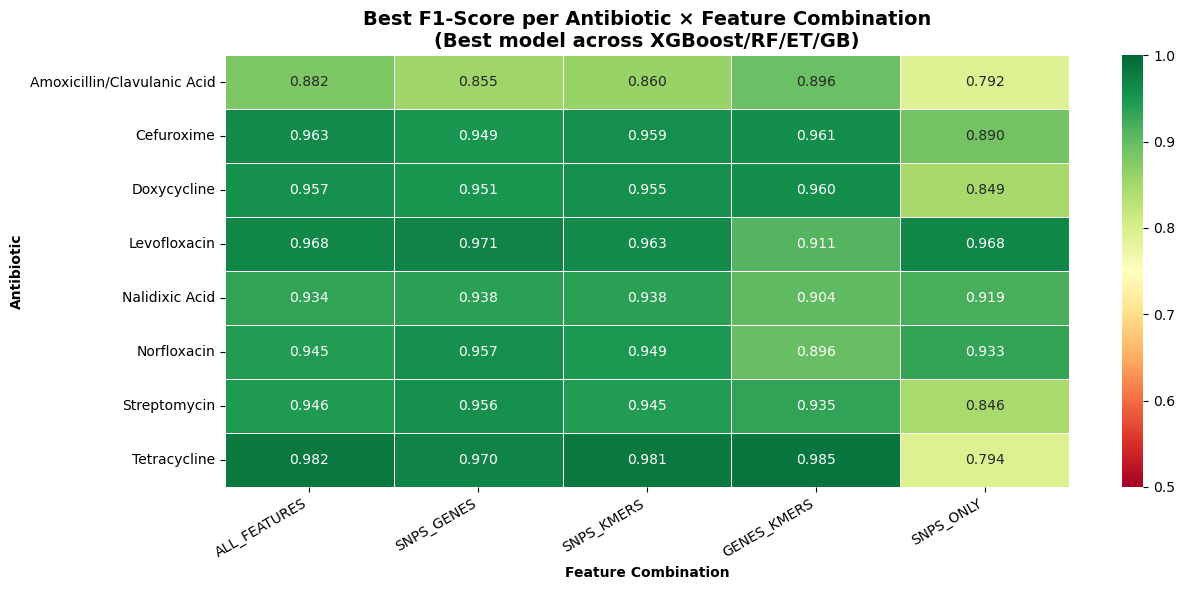

✓ Saved: f1_heatmap.png


In [8]:
# ── CELL 8: Heatmap — F1 by Antibiotic × Dataset ─────────────────────────

# Use best model F1 per antibiotic × dataset combination
heatmap_data = (
    results_df
    .groupby(['Antibiotic', 'Dataset'])['F1']
    .max()
    .unstack('Dataset')
)

# Reorder columns
col_order = [c for c in DATASET_TYPES if c in heatmap_data.columns]
heatmap_data = heatmap_data[col_order]

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(
    heatmap_data,
    annot=True, fmt='.3f', cmap='RdYlGn',
    vmin=0.5, vmax=1.0,
    linewidths=0.5, ax=ax
)
ax.set_title('Best F1-Score per Antibiotic × Feature Combination\n(Best model across XGBoost/RF/ET/GB)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Combination', fontweight='bold')
ax.set_ylabel('Antibiotic', fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'f1_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: f1_heatmap.png')

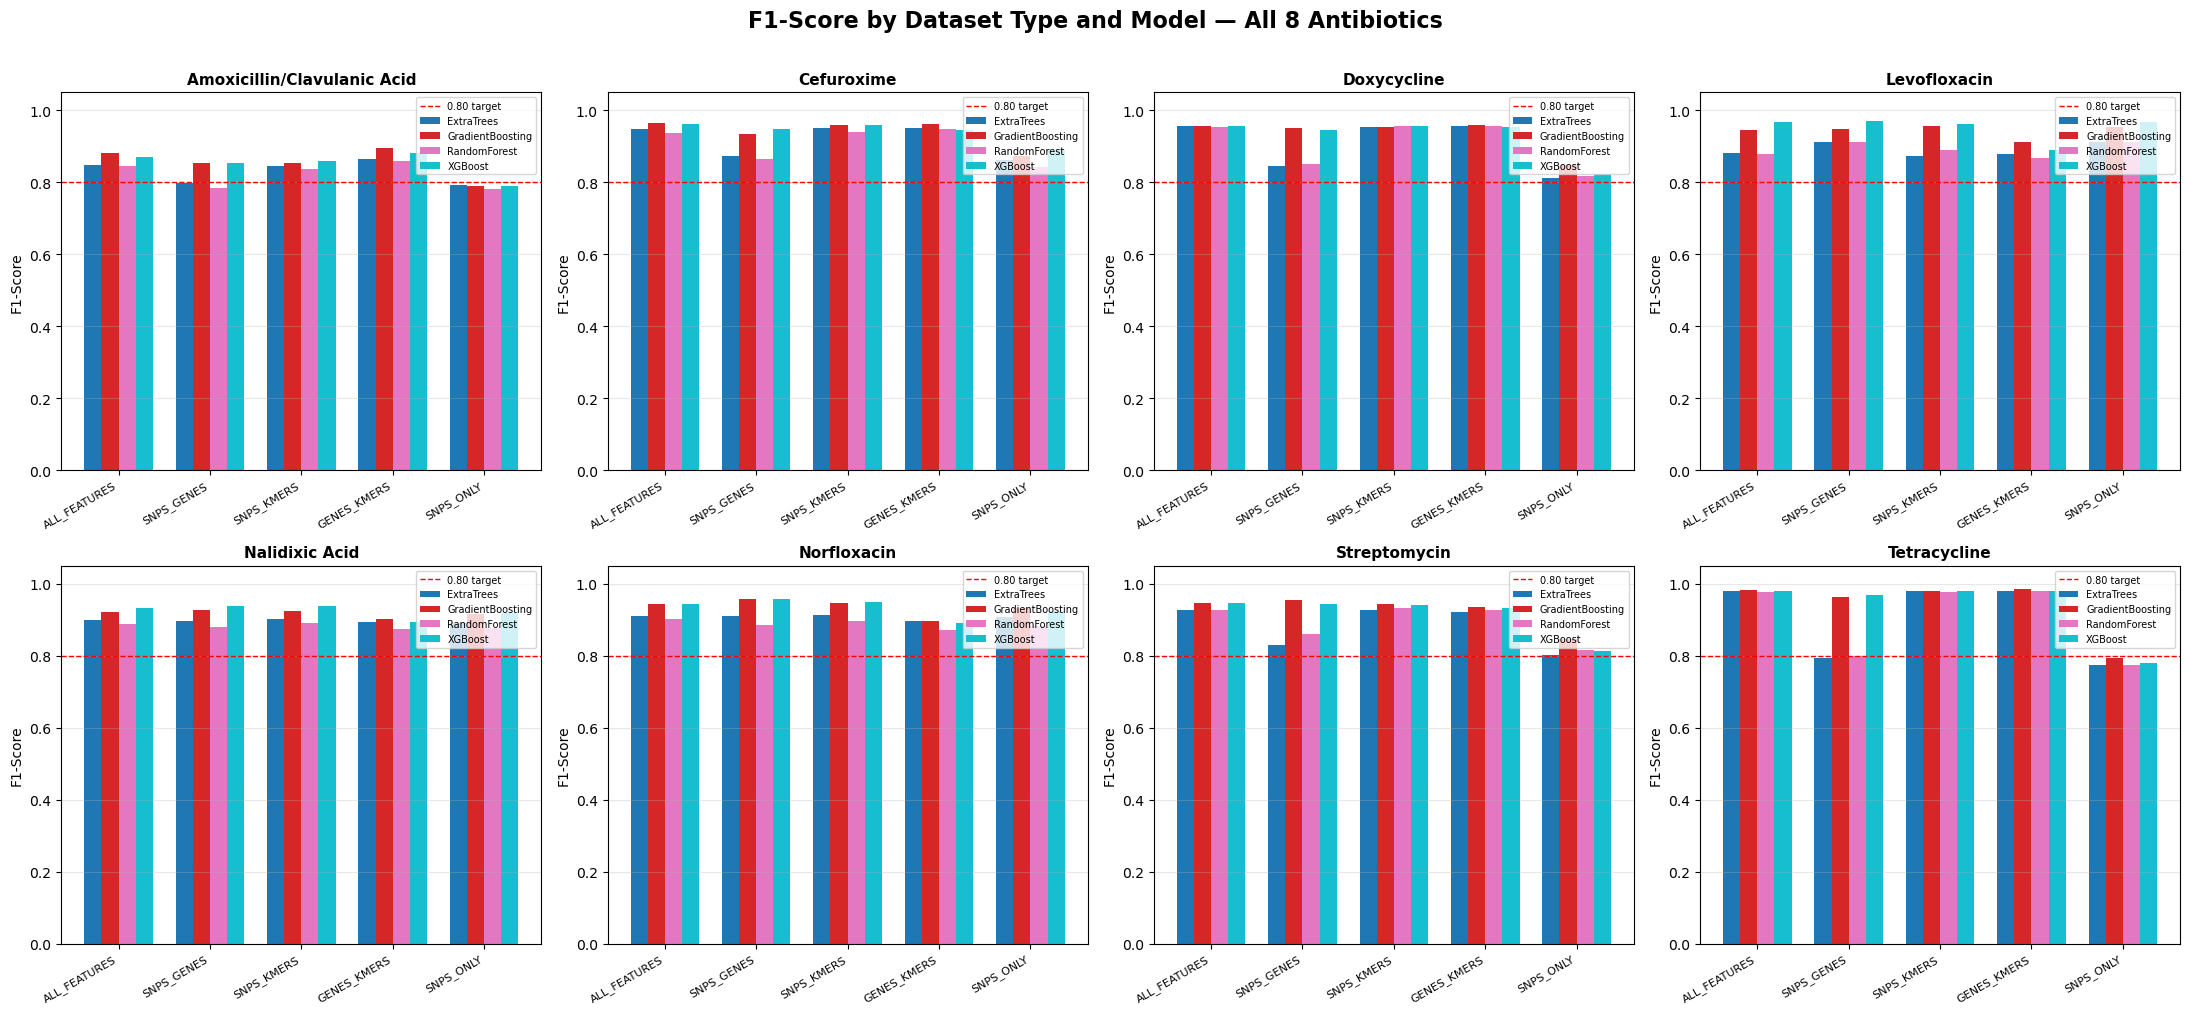

✓ Saved: f1_by_antibiotic_model.png


In [9]:
# ── CELL 9: Bar Chart — F1 by Model per Antibiotic ────────────────────────
# One subplot per antibiotic, bars = dataset types, grouped by model

antibiotics_list = list(ANTIBIOTIC_FULL_NAMES.values())
n_ab = len(antibiotics_list)
ncols = 4
nrows = (n_ab + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(22, nrows * 5))
axes = axes.flatten()

for idx, ab_full in enumerate(antibiotics_list):
    ax = axes[idx]
    ab_data = results_df[results_df['Antibiotic'] == ab_full]
    
    pivot = ab_data.pivot_table(index='Dataset', columns='Model', values='F1')
    pivot = pivot.reindex(index=DATASET_TYPES, fill_value=np.nan)

    pivot.plot(kind='bar', ax=ax, width=0.75, colormap='tab10')
    ax.set_title(ab_full, fontweight='bold', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('F1-Score')
    ax.set_ylim(0, 1.05)
    ax.axhline(0.8, color='red', linestyle='--', linewidth=1, label='0.80 target')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=8)
    ax.legend(fontsize=7)
    ax.grid(axis='y', alpha=0.3)

# Hide unused subplots
for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('F1-Score by Dataset Type and Model — All 8 Antibiotics',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'f1_by_antibiotic_model.png'),
            dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: f1_by_antibiotic_model.png')

In [14]:
# ── CELL 10: PHASE 2 — SNP Feature Selection ─────────────────────────────
# Goal: reduce SNP features to prevent overfitting
# Method: train ExtraTrees on the SNP-containing datasets,
#         keep only top-N features by importance
# Run this AFTER reviewing Phase 1 results above

from sklearn.feature_selection import SelectFromModel

# Settings — adjust after reviewing Phase 1 results
TOP_N_SNPS = 10000         # hard cap on SNP features to keep
SNP_DATASET_SUFFIX = 'SNPS_ONLY'  # which dataset to select SNPs from

snp_importance_results = {}

for ab_prefix, label_col in ANTIBIOTICS.items():
    filepath = build_filepath(ab_prefix, SNP_DATASET_SUFFIX)

    if not os.path.exists(filepath):
        print(f'  ⚠ Skipping {ab_prefix} — file not found')
        continue

    ab_full = ANTIBIOTIC_FULL_NAMES[ab_prefix]
    print(f'\n── {ab_full} ──────────────────────')

    X, y = load_data(filepath, label_col)
    feature_names = X.columns.tolist()

    # Train ExtraTrees on full SNP set
    et = ExtraTreesClassifier(
        n_estimators=200, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1
    )
    et.fit(X, y)

    # Rank features by importance
    importance_df = pd.DataFrame({
        'Feature'   : feature_names,
        'Importance': et.feature_importances_
    }).sort_values('Importance', ascending=False).reset_index(drop=True)

    top_features = importance_df.head(TOP_N_SNPS)['Feature'].tolist()

    print(f'  Total SNP features : {len(feature_names)}')
    print(f'  Kept top {TOP_N_SNPS}         : {len(top_features)}')
    print(f'  Top 10 SNPs:')
    for i, row in importance_df.head(10).iterrows():
        print(f'    {i+1:>3}. {row["Feature"]:40s}  {row["Importance"]:.6f}')

    snp_importance_results[ab_prefix] = {
        'importance_df' : importance_df,
        'top_features'  : top_features,
        'n_total'       : len(feature_names),
    }

    # Save importance ranking per antibiotic
    out = os.path.join(DATA_DIR, f'{ab_prefix}_snp_importance.csv')
    importance_df.to_csv(out, index=False)
    print(f'  ✓ Saved: {out}')

print('\n✓ SNP feature selection complete')


── Amoxicillin/Clavulanic Acid ──────────────────────
  ✓ 571 samples × 35476 features
    Susceptible (0): 319  |  Resistant (1): 252
  Total SNP features : 35476
  Kept top 10000         : 10000
  Top 10 SNPs:
      1. NC_000913_3165735                         0.006066
      2. NC_000913_3832753                         0.005752
      3. NC_000913_3296252                         0.003828
      4. NC_000913_3295235                         0.003755
      5. NC_000913_1869977                         0.003572
      6. NC_000913_2803237                         0.003389
      7. NC_000913_2296932                         0.003128
      8. NC_000913_4117497                         0.003061
      9. NC_000913_964580                          0.002922
     10. NC_000913_794685                          0.002812
  ✓ Saved: C:/Users/USER/Downloads/E_coli/datasets/final_merged_outputs\amoxicillin_snp_importance.csv

── Cefuroxime ──────────────────────
  ✓ 571 samples × 35476 features
    Susceptib

In [15]:
# ── CELL 11: Re-train SNPS_ONLY with Reduced SNP Features ─────────────────
# Compare performance before vs after SNP reduction

snp_comparison_rows = []

for ab_prefix, label_col in ANTIBIOTICS.items():
    if ab_prefix not in snp_importance_results:
        continue

    filepath   = build_filepath(ab_prefix, SNP_DATASET_SUFFIX)
    ab_full    = ANTIBIOTIC_FULL_NAMES[ab_prefix]
    top_feats  = snp_importance_results[ab_prefix]['top_features']

    print(f'\n── {ab_full} (reduced SNPs) ────────────────────────')

    X_full, y = load_data(filepath, label_col)
    X_reduced  = X_full[top_feats]

    # Full SNP CV (already in all_results — retrieve mean F1)
    full_f1 = results_df[
        (results_df['Antibiotic'] == ab_full) &
        (results_df['Dataset']    == SNP_DATASET_SUFFIX)
    ]['F1'].max()

    # Reduced SNP CV
    reduced_cv      = run_cv(X_reduced, y, label=f'{ab_full} reduced SNPs')
    reduced_summary = summarize(reduced_cv)

    best_reduced_f1 = max(v['f1'][0] for v in reduced_summary.values())
    best_reduced_model = max(reduced_summary, key=lambda m: reduced_summary[m]['f1'][0])

    print(f'  Full SNPs ({snp_importance_results[ab_prefix]["n_total"]} features)  → best F1: {full_f1:.3f}')
    print(f'  Reduced   ({TOP_N_SNPS} features)              → best F1: {best_reduced_f1:.3f}  ({best_reduced_model})')

    snp_comparison_rows.append({
        'Antibiotic'      : ab_full,
        'Full_SNP_Features': snp_importance_results[ab_prefix]['n_total'],
        'Reduced_Features' : TOP_N_SNPS,
        'Full_Best_F1'     : round(full_f1, 4),
        'Reduced_Best_F1'  : round(best_reduced_f1, 4),
        'F1_Change'        : round(best_reduced_f1 - full_f1, 4),
        'Best_Model'       : best_reduced_model,
    })

snp_comp_df = pd.DataFrame(snp_comparison_rows)

print('\n' + '='*90)
print('SNP FEATURE REDUCTION — BEFORE vs AFTER')
print('='*90)
print(snp_comp_df.to_string(index=False))

out = os.path.join(DATA_DIR, 'snp_reduction_comparison.csv')
snp_comp_df.to_csv(out, index=False)
print(f'\n✓ Saved: {out}')


── Amoxicillin/Clavulanic Acid (reduced SNPs) ────────────────────────
  ✓ 571 samples × 35476 features
    Susceptible (0): 319  |  Resistant (1): 252
  Full SNPs (35476 features)  → best F1: 0.792
  Reduced   (10000 features)              → best F1: 0.806  (XGBoost)

── Cefuroxime (reduced SNPs) ────────────────────────
  ✓ 571 samples × 35476 features
    Susceptible (0): 360  |  Resistant (1): 211
  Full SNPs (35476 features)  → best F1: 0.890
  Reduced   (10000 features)              → best F1: 0.895  (XGBoost)

── Doxycycline (reduced SNPs) ────────────────────────
  ✓ 571 samples × 35476 features
    Susceptible (0): 172  |  Resistant (1): 399
  Full SNPs (35476 features)  → best F1: 0.849
  Reduced   (10000 features)              → best F1: 0.853  (GradientBoosting)

── Levofloxacin (reduced SNPs) ────────────────────────
  ✓ 571 samples × 35476 features
    Susceptible (0): 384  |  Resistant (1): 187
  Full SNPs (35476 features)  → best F1: 0.968
  Reduced   (10000 features) 

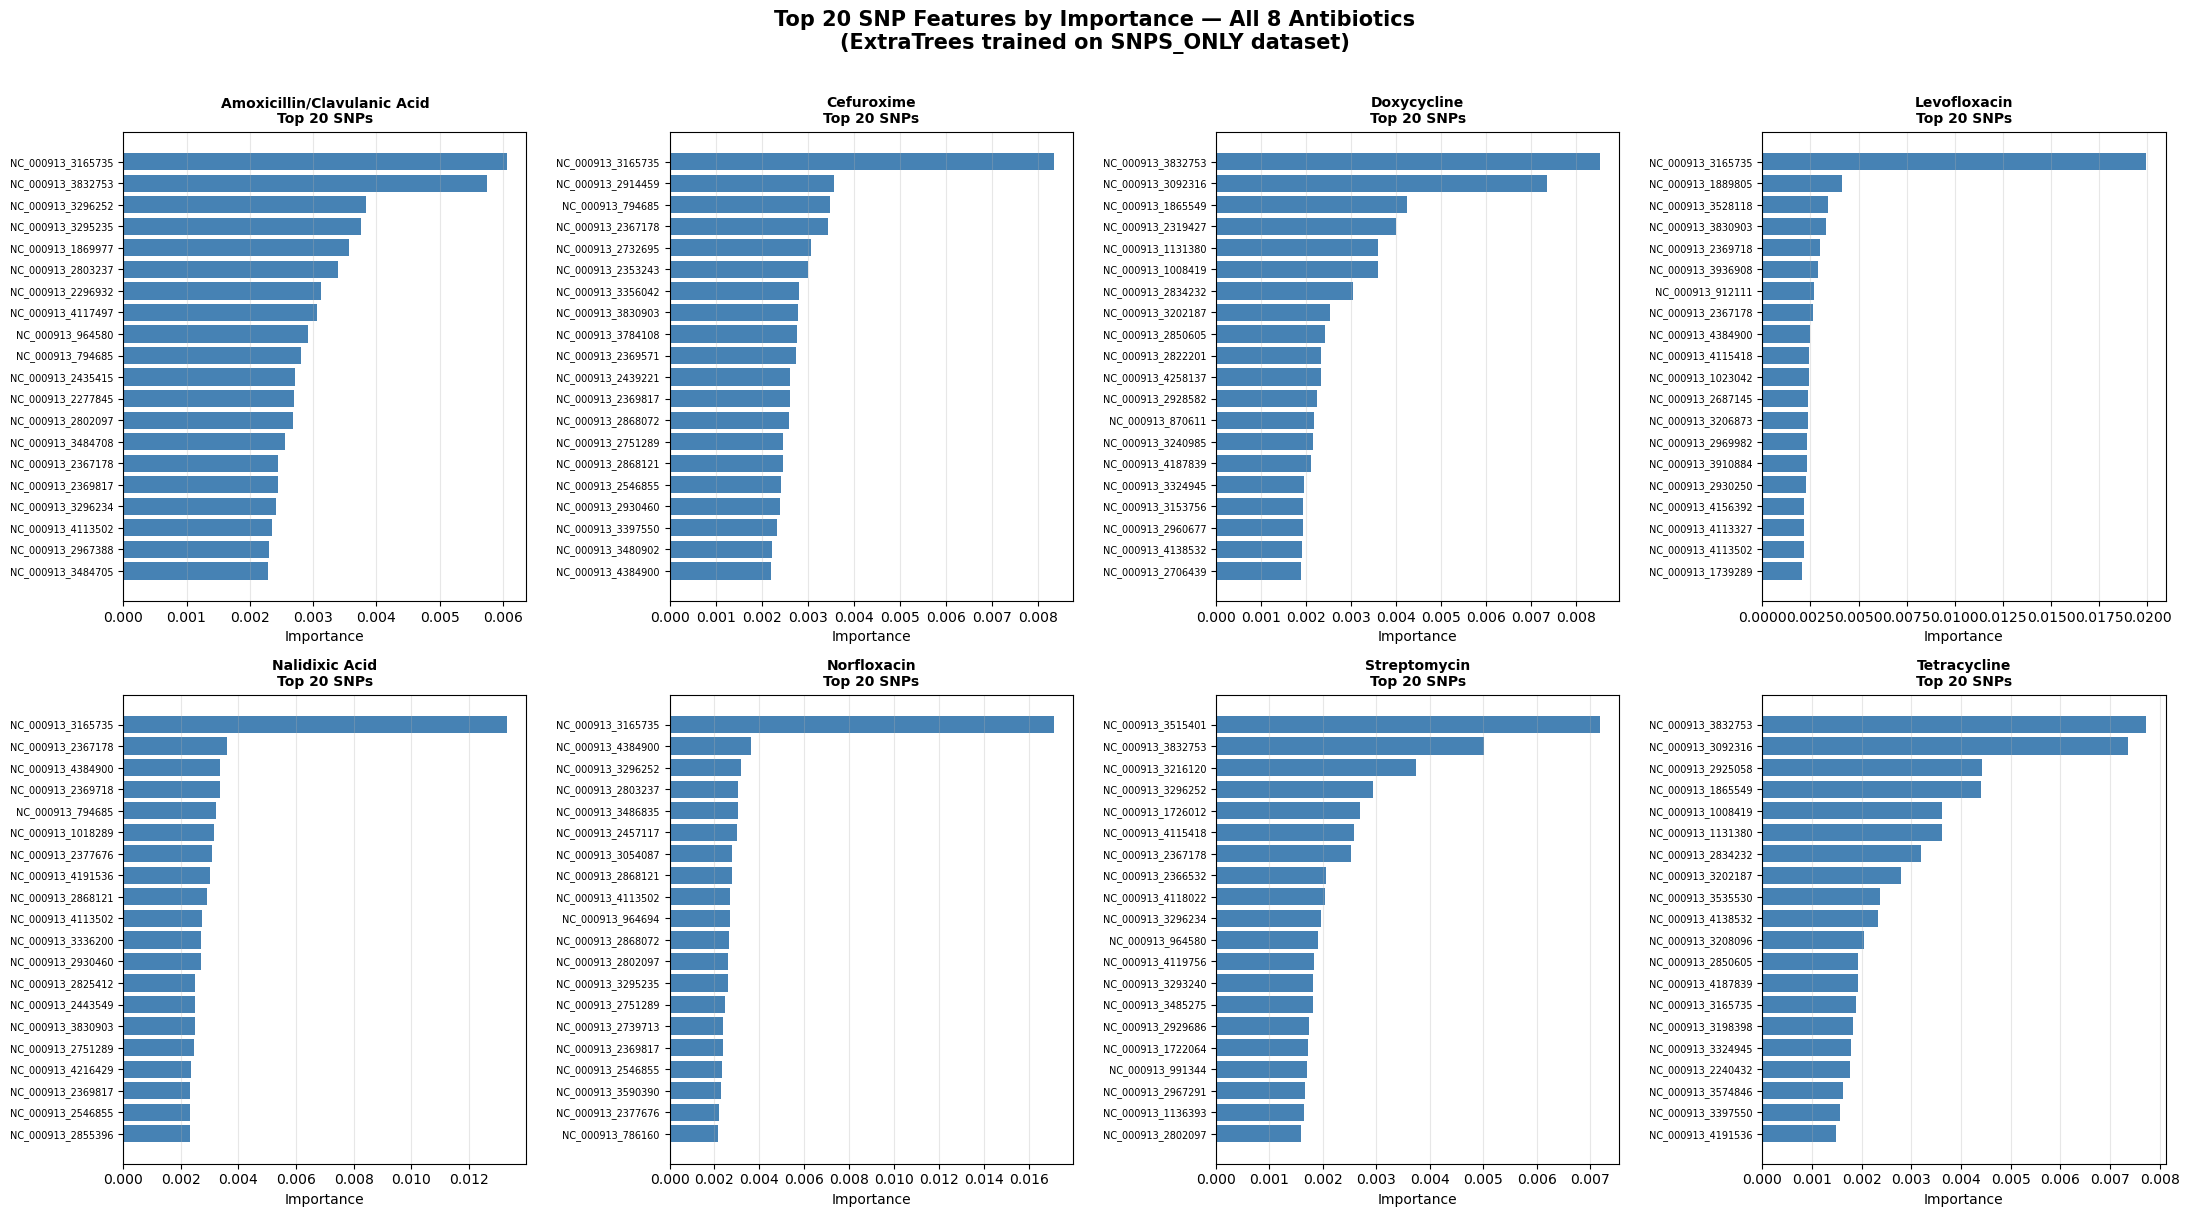

✓ Saved: snp_importance_all_antibiotics.png


In [16]:
# ── CELL 12: SNP Importance Plot — All 8 Antibiotics ──────────────────────

n_ab  = len(snp_importance_results)
ncols = 4
nrows = (n_ab + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(22, nrows * 6))
axes = axes.flatten()

for idx, (ab_prefix, res) in enumerate(snp_importance_results.items()):
    ax  = axes[idx]
    top = res['importance_df'].head(20)

    ax.barh(range(len(top)), top['Importance'].values[::-1], color='steelblue')
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top['Feature'].values[::-1], fontsize=7)
    ax.set_title(f'{ANTIBIOTIC_FULL_NAMES[ab_prefix]}\nTop 20 SNPs',
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('Importance')
    ax.grid(axis='x', alpha=0.3)

for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f'Top 20 SNP Features by Importance — All 8 Antibiotics\n'
             f'(ExtraTrees trained on SNPS_ONLY dataset)',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, 'snp_importance_all_antibiotics.png'),
            dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: snp_importance_all_antibiotics.png')

In [17]:
# ── CELL 13: Final Summary ────────────────────────────────────────────────

print('='*90)
print('FINAL SUMMARY')
print('='*90)
print(f'Total combinations trained : {len(results_df)}')
print(f'Best overall F1            : {results_df["F1"].max():.3f}')
print(f'Worst overall F1           : {results_df["F1"].min():.3f}')
print(f'Mean F1 across all         : {results_df["F1"].mean():.3f}')

print('\nFiles saved:')
saved = [
    'training_results_all_antibiotics.csv',
    'best_model_per_antibiotic.csv',
    'snp_reduction_comparison.csv',
    'f1_heatmap.png',
    'f1_by_antibiotic_model.png',
    'snp_importance_all_antibiotics.png',
]
for f in saved:
    print(f'  ✓ {f}')

print('\nNext steps:')
print('  1. Review f1_heatmap.png — identify best feature combo per antibiotic')
print('  2. Review snp_reduction_comparison.csv — confirm SNP reduction is safe')
print('  3. Use best model + best dataset for final training and feature importance export')

FINAL SUMMARY
Total combinations trained : 160
Best overall F1            : 0.985
Worst overall F1           : 0.774
Mean F1 across all         : 0.906

Files saved:
  ✓ training_results_all_antibiotics.csv
  ✓ best_model_per_antibiotic.csv
  ✓ snp_reduction_comparison.csv
  ✓ f1_heatmap.png
  ✓ f1_by_antibiotic_model.png
  ✓ snp_importance_all_antibiotics.png

Next steps:
  1. Review f1_heatmap.png — identify best feature combo per antibiotic
  2. Review snp_reduction_comparison.csv — confirm SNP reduction is safe
  3. Use best model + best dataset for final training and feature importance export
